       r_all  r_responders
mean   0.251         0.423
knn    0.159         0.333
ridge  0.264         0.498
rf     0.296         0.544
xgb    0.251         0.482
mlp2   0.225         0.436


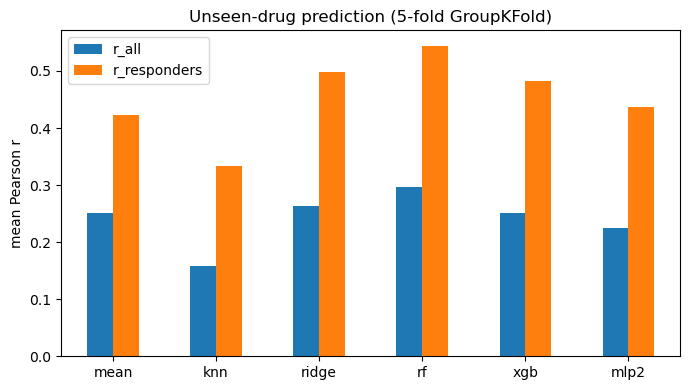

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

X = pd.read_csv("../data/processed/X_features.csv", index_col=0)
groups = pd.read_csv("../data/processed/row_groups.csv", index_col=0)["group"]
meta = pd.read_csv("../data/processed/response_meta.csv", index_col=0)
scores = pd.read_csv("../results/tables/06_model_scores.csv", index_col=0)

models = ["mean", "knn", "ridge", "rf", "xgb", "mlp2"]
resp = scores[scores["responder"]]

summary = pd.DataFrame({
    "r_all": [scores[f"r_{m}"].mean() for m in models],
    "r_responders": [resp[f"r_{m}"].mean() for m in models],
}, index=models).round(3)
print(summary)
summary.to_csv("../results/tables/07_summary.csv")

summary.plot.bar(figsize=(7, 4))
plt.ylabel("mean Pearson r")
plt.title("Unseen-drug prediction (5-fold GroupKFold)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/figures/07_model_comparison.png", dpi=150)
plt.show()

In [5]:
scores["dose"] = meta["dose"]
resp = scores[scores["responder"]]

by_dose = resp.groupby("dose")[["r_mean", "r_rf"]].mean().round(3)
by_dose["n_responders"] = resp.groupby("dose").size()
print(by_dose)

         r_mean   r_rf  n_responders
dose                                
10.0      0.355  0.522            25
100.0     0.359  0.503            40
1000.0    0.484  0.586            46
10000.0   0.438  0.547            98


In [6]:
bits = [c for c in X.columns if c != "log_dose"]
B = X[bits].values.astype(bool)
max_sim = np.zeros(len(X))

gkf = GroupKFold(n_splits=5)
for tr, te in gkf.split(X, groups=groups):
    for i in te:
        sim = (B[i] & B[tr]).sum(1) / (B[i] | B[tr]).sum(1)
        max_sim[i] = sim.max()

scores["max_sim"] = max_sim
scores["sim_bin"] = pd.cut(max_sim, [0, 0.3, 0.5, 0.7, 1.0])

resp = scores[scores["responder"]]
by_sim = resp.groupby("sim_bin", observed=True)[["r_mean", "r_knn", "r_rf"]].mean().round(3)
by_sim["n"] = resp.groupby("sim_bin", observed=True).size()
print(by_sim)

scores.to_csv("../results/tables/07_scores_detailed.csv")

            r_mean  r_knn   r_rf   n
sim_bin                             
(0.0, 0.3]   0.410  0.200  0.470  97
(0.3, 0.5]   0.475  0.342  0.582  75
(0.5, 0.7]   0.434  0.614  0.605  21
(0.7, 1.0]   0.246  0.735  0.738  16


In [9]:
import anndata as ad

obs = ad.read_h5ad("../data/raw/sciplex3.h5ad", backed="r").obs
cls = (obs[["product_name", "pathway_level_1"]]
       .drop_duplicates("product_name")
       .set_index("product_name")["pathway_level_1"])
cls.to_csv("../data/processed/drug_classes.csv")   # save for later

scores["class"] = meta["product_name"].map(cls)
resp = scores[scores["responder"]]

by_class = resp.groupby("class", observed=True)[["r_mean", "r_rf"]].mean().round(3)
by_class["n"] = resp.groupby("class", observed=True).size()
by_class = by_class[by_class["n"] >= 5].sort_values("r_rf", ascending=False)
print(by_class)

                                       r_mean   r_rf   n
class                                                   
Epigenetic regulation                   0.537  0.695  59
Protein folding & Protein degradation   0.194  0.678   7
Cell cycle regulation                   0.458  0.639  58
JAK/STAT signaling                      0.342  0.481  16
Tyrosine kinase signaling               0.387  0.370  33
Apoptotic regulation                    0.269  0.316   7
DNA damage & DNA repair                 0.298  0.316  14
Nuclear receptor signaling              0.349  0.208   5


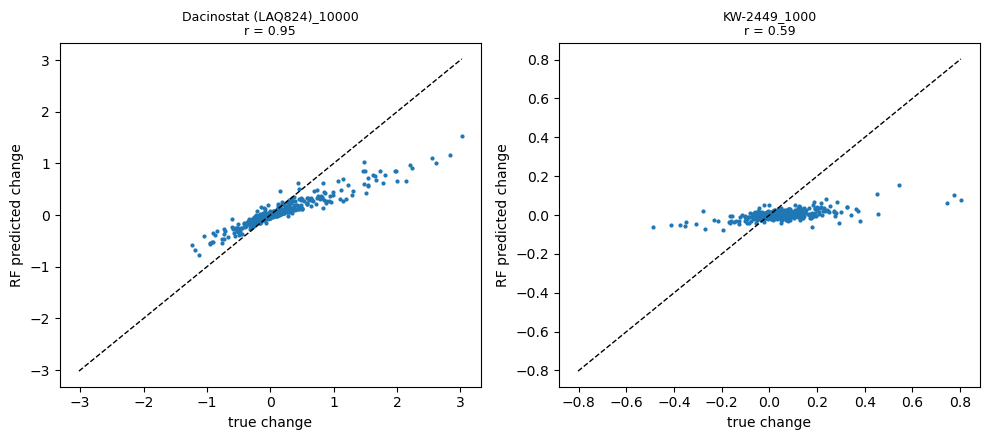

In [8]:
Y = pd.read_csv("../data/processed/response_delta.csv", index_col=0)
P_rf = np.load("../results/models/P_rf.npy")

resp = scores[scores["responder"]]
best = meta.loc[resp.index, "strength"].idxmax()
typical = (resp["r_rf"] - resp["r_rf"].median()).abs().idxmin()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, row in zip(axes, [best, typical]):
    i = Y.index.get_loc(row)
    ax.scatter(Y.values[i], P_rf[i], s=4)
    lim = np.abs(Y.values[i]).max()
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)   # diagonal = perfect
    ax.set_title(f"{row}\nr = {scores.loc[row, 'r_rf']:.2f}", fontsize=9)
    ax.set_xlabel("true change")
    ax.set_ylabel("RF predicted change")
plt.tight_layout()
plt.savefig("../results/figures/07_example_predictions.png", dpi=150)
plt.show()

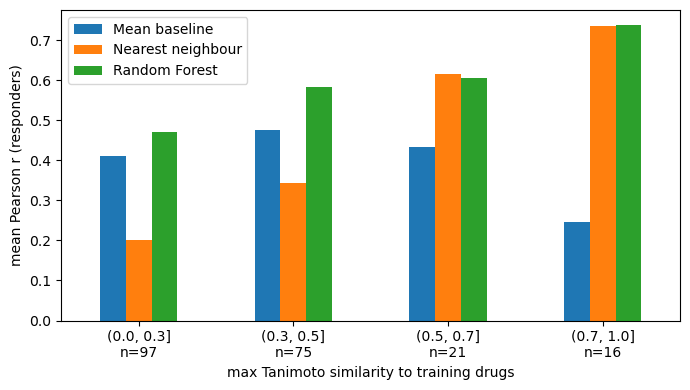

In [13]:
ax = by_sim[["r_mean", "r_knn", "r_rf"]].plot.bar(figsize=(7, 4))
ax.legend(["Mean baseline", "Nearest neighbour", "Random Forest"])
ax.set_xticklabels([f"{b}\nn={n}" for b, n in zip(by_sim.index.astype(str), by_sim["n"])], rotation=0)
ax.set_ylabel("mean Pearson r (responders)")
ax.set_xlabel("max Tanimoto similarity to training drugs")
plt.tight_layout()
plt.savefig("../results/figures/07_by_similarity.png", dpi=150)
plt.show()

In [11]:
by_class.to_csv("../results/tables/07_by_class.csv")
by_dose.to_csv("../results/tables/07_by_dose.csv")
by_sim.to_csv("../results/tables/07_by_similarity.csv")